# 1.1 — Ingesta: serie diaria de Open-Meteo (Hermosillo)

El SMN/CONAGUA solo publica **promedios mensuales** por estación (notebook 1.0). Para detectar **olas de calor** se necesitan datos **diarios**, así que se usa el archivo histórico de Open-Meteo.

Open-Meteo es un **reanálisis**: un modelo que estima el clima de cada día para un punto del mapa. No es una estación.

| | |
|---|---|
| **Fuente** | Open-Meteo Historical Weather API — `https://archive-api.open-meteo.com/v1/archive` |
| **Punto** | Centro de Hermosillo, lat `29.07`, lon `-110.95` |
| **Periodo** | 1991-01-01 a 2020-12-31 (1991–2014 solo para la climatología de los umbrales P95; el análisis usa 2015–2020) |
| **Zona horaria** | `America/Hermosillo` |
| **Variables** | `temperature_2m_max` → `tmax_c`, `temperature_2m_min` → `tmin_c`, `relative_humidity_2m_mean` → `humedad_rel_pct` |
| **Salida** | `data/raw/openmeteo_hermosillo_daily_1991_2020.csv` (una fila por día) |

**Ojo:** estas Tmax/Tmin diarias **no** son la `temp_max_media_c` del panel. Esa es la Tmax mensual del SMN (notebook 1.0). El procesamiento de esta serie está en `02_procesamiento/2.1-procesamiento-calor-openmeteo.ipynb`.

## Configuración e imports

La descarga la hace `load_openmeteo_daily()` de `panel.py`, la misma función que usan el procesamiento y el panel. Si el CSV ya existe en `data/raw/`, lo lee y **no** vuelve a descargar.

In [1]:
from pathlib import Path
import sys

ROOT_DIR = Path.cwd().parent.parent  # notebooks/01_ingesta/ -> raíz del proyecto
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))

import matplotlib.pyplot as plt
import pandas as pd

from sonora_health_climate_eda.config import PANEL_END_YEAR, PANEL_START_YEAR, RAW_DATA_DIR
from sonora_health_climate_eda.panel import CLIMATOLOGY_START, load_openmeteo_daily

CACHE = RAW_DATA_DIR / "openmeteo_hermosillo_daily_1991_2020.csv"
print("Archivo:", CACHE)
print("Ya existe:", CACHE.exists())

Archivo: /Users/benancio/Documents/sonora-health-climate-eda/data/raw/openmeteo_hermosillo_daily_1991_2020.csv
Ya existe: True


## Descarga (o lectura del archivo existente)

Para volver a descargar desde cero, borra a mano el CSV de `data/raw/` y corre esta celda otra vez.

In [2]:
om = load_openmeteo_daily()
print(f"Filas: {len(om):,} | Columnas: {list(om.columns)}")
om.head()

Filas: 10,958 | Columnas: ['fecha', 'tmax_c', 'tmin_c', 'humedad_rel_pct']


,fecha,tmax_c,tmin_c,humedad_rel_pct
0,1991-01-01,23.1,9.1,75
1,1991-01-02,24.4,9.4,70
2,1991-01-03,25.8,12.3,67
3,1991-01-04,21.8,13.8,71
4,1991-01-05,18.9,14.6,91


## Validación

Se revisa que:
1. Estén **todos los días** del periodo, sin fechas duplicadas.
2. No haya **valores faltantes**.
3. Los valores estén en **rangos físicos** razonables para Hermosillo.
4. La Tmax de cada día sea **mayor o igual** que la Tmin.

In [3]:
esperadas = pd.date_range(CLIMATOLOGY_START, "2020-12-31", freq="D")
faltan = esperadas.difference(om["fecha"])
duplicadas = om["fecha"].duplicated().sum()

print(f"Rango: {om['fecha'].min().date()} a {om['fecha'].max().date()}")
print(f"Días esperados: {len(esperadas):,} | Días en el archivo: {len(om):,}")
print(f"Días faltantes: {len(faltan)} | Fechas duplicadas: {duplicadas}")
print("\nValores faltantes por columna:")
print(om.isna().sum())

Rango: 1991-01-01 a 2020-12-31
Días esperados: 10,958 | Días en el archivo: 10,958
Días faltantes: 0 | Fechas duplicadas: 0

Valores faltantes por columna:
fecha              0
tmax_c             0
tmin_c             0
humedad_rel_pct    0
dtype: int64


In [4]:
rangos = {
    "tmax_c": (-10, 55),
    "tmin_c": (-15, 40),
    "humedad_rel_pct": (0, 100),
}
for col, (lo, hi) in rangos.items():
    fuera = (~om[col].between(lo, hi) & om[col].notna()).sum()
    print(f"{col}: {fuera} días fuera de [{lo}, {hi}]")

invertidos = (om["tmax_c"] < om["tmin_c"]).sum()
print(f"Días con Tmax < Tmin: {invertidos}")

om[list(rangos)].describe().round(1)

tmax_c: 0 días fuera de [-10, 55]
tmin_c: 0 días fuera de [-15, 40]
humedad_rel_pct: 0 días fuera de [0, 100]
Días con Tmax < Tmin: 0


,tmax_c,tmin_c,humedad_rel_pct
count,10958.0,10958.0,10958.0
mean,31.6,17.5,44.1
std,6.7,6.8,17.9
min,8.5,-0.6,6.0
25%,26.5,11.6,30.0
50%,32.4,16.9,42.0
75%,37.0,24.2,57.0
max,47.1,31.1,97.0


In [5]:
problemas = {
    "días faltantes": len(faltan),
    "fechas duplicadas": int(duplicadas),
    "valores faltantes": int(om[list(rangos)].isna().sum().sum()),
    "días con Tmax < Tmin": int(invertidos),
}
for nombre, n in problemas.items():
    print(("OK   " if n == 0 else "REVISAR ") + f"{nombre}: {n}")

OK   días faltantes: 0
OK   fechas duplicadas: 0
OK   valores faltantes: 0
OK   días con Tmax < Tmin: 0


## Vista rápida de la ventana de análisis

Tmax y Tmin diarias en la ventana del panel. Se debe ver el ciclo anual: veranos con Tmax cerca de 45 °C e inviernos más frescos.

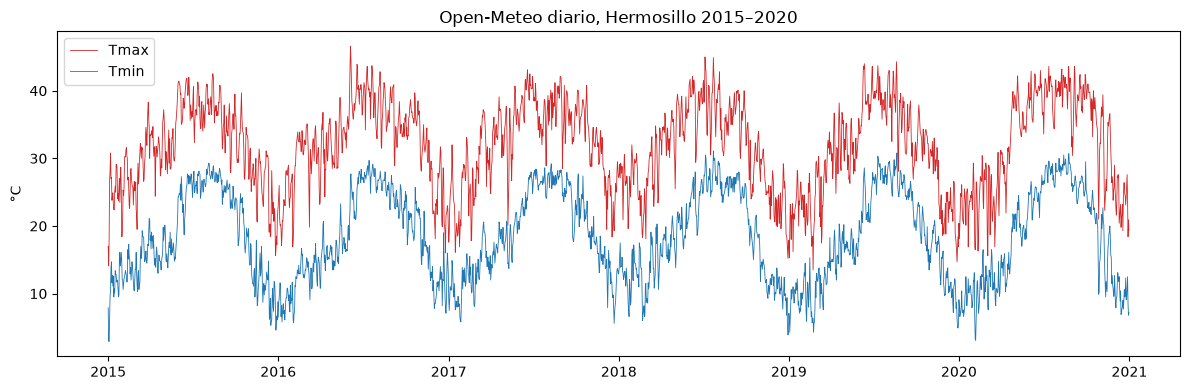

In [6]:
ventana = om[om["fecha"].dt.year.between(PANEL_START_YEAR, PANEL_END_YEAR)]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(ventana["fecha"], ventana["tmax_c"], lw=0.6, color="tab:red", label="Tmax")
ax.plot(ventana["fecha"], ventana["tmin_c"], lw=0.6, color="tab:blue", label="Tmin")
ax.set_ylabel("°C")
ax.set_title(f"Open-Meteo diario, Hermosillo {PANEL_START_YEAR}–{PANEL_END_YEAR}")
ax.legend()
plt.tight_layout()
plt.show()

## Siguiente paso

La serie queda lista en `data/raw/`. El cálculo de umbrales P95, heat index y olas de calor, y el resumen mensual que entra al panel, están en `02_procesamiento/2.1-procesamiento-calor-openmeteo.ipynb`.